In [164]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv

if os.environ['AICREDITS_API_KEY']:
    
    print("AICredits API Key is set.")
else:
    raise ValueError("AICredits API Key is not set.")

AICredits API Key is set.


In [165]:
llm = ChatOpenAI(
    model="openai/gpt-5-nano",
    base_url="https://api.aicredits.in/v1",
    api_key=os.environ["AICREDITS_API_KEY"],
)

In [166]:
import os
from typing import TypedDict, List, Annotated
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage, BaseMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun
from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from ddgs import DDGS
from IPython.display import Image, display

## **TOOLS**
### **DuckDuckGo Search Tool**

In [167]:
@tool
def search_duckduckgo(query: str) -> str:
    """This tool searches the latest news on DuckDuckGo for the given query and returns the results."""
    # Fix 2: DDGS is not callable and has no .invoke() method; use ddgs.text() or ddgs.news()
    with DDGS() as ddgs:
        results = list(ddgs.text(query, max_results=5))
        return str(results) if results else "No results found."

### **Arxiv Query Tool**

In [168]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_tool(query: str) -> str:
    """This tool allows you to query the arXiv database for research papers"""
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)

### **Wikipedia Search Tool**

In [169]:

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_tool(query: str):

    """This tool allows you to search Wikipedia for information on a given topic."""
    wiki_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wiki_query.invoke(query)

### **Custom Tool**

In [170]:
@tool
def personal_info(name: str):
    """Use this tool to get personal information about Alice, Bob or Charlie."""
    info = {
        "Alice": "Alice is a software engineer with 5 years of experience in AI.",
        "Bob": "Bob is a data scientist who loves working with large datasets.",
        "Charlie": "Charlie is a product manager with a background in tech startups." 
    }
    return info.get(name, "No information available for this person.")

### **TOOL BINDING**

In [171]:
tools = [search_duckduckgo, arxiv_tool, wiki_tool, personal_info]
llm_with_tools = llm.bind_tools(tools)

### **LangGraph Creation**

**Create Schema**

In [172]:
from typing import TypedDict, List

class graph_schema(TypedDict):
    messages: List

**Create Node Functions**

In [173]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
def llm_node(state: graph_schema) -> graph_schema:
    messages = state["messages"]

    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", "You are a helpful assistant that can use tools to answer questions."),
            MessagesPlaceholder(variable_name="messages")
        ]    
    )

    chain = prompt | llm_with_tools

    response = chain.invoke({"messages": messages})
    state["messages"] = messages + [response]
    return state

In [174]:
from langchain_core.messages import ToolMessage
def tool_node(state: graph_schema) -> dict:
    messages = state["messages"]
    tools_by_name = {t.name: t for t in tools}
    tool_results = []

    for tool_call in messages[-1].tool_calls:
        selected_tool = tools_by_name[tool_call["name"]]
        observation = selected_tool.invoke(tool_call["args"])
        
        # Fix 4: Cast observation to str() so ToolMessage content validation never fails
        tool_results.append(
            ToolMessage(content=str(observation), tool_call_id=tool_call["id"])
        )
        
    return {"messages": messages + tool_results}

**Create Conditional Edge Function**

In [175]:
def if_tool_call(state: graph_schema) -> str:

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

**Create State Graph**

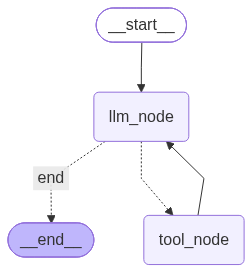

In [176]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

# Add node to the graph
graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)

# Add edges between them
graph.add_edge(START, "llm_node")
graph.add_conditional_edges("llm_node", if_tool_call,{"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node", "llm_node")
# graph.add_edge("llm_node", END)

react_graph = graph.compile()

from IPython.display import Image, display
Image(react_graph.get_graph().draw_mermaid_png())

**Graph Invocation**

In [177]:
from langchain_core.messages import HumanMessage
react_graph.invoke({"messages": [HumanMessage(content="What is the latest news on AI?")]})

{'messages': [HumanMessage(content='What is the latest news on AI?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 284, 'prompt_tokens': 250, 'total_tokens': 534, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 256, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'cost': 0.0142429829292036, 'cost_details': {'completion_cost_inr': 0.012831109125753602, 'prompt_cost_inr': 0.0014118738034500002}, 'latency_ms': 1930}, 'model_provider': 'openai', 'model_name': 'gpt-5-nano-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EaDwCgA44ZZPf55spyXGl06aLyIgx', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a14d87-8fc0-7381-a7dc-d21d43348e8e

In [178]:
for chunk in react_graph.stream(
    {"messages": [HumanMessage(content="What is the latest news on AI?")]},
    stream_mode="updates"
):
    print(chunk)

{'llm_node': {'messages': [HumanMessage(content='What is the latest news on AI?', additional_kwargs={}, response_metadata={}), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 220, 'prompt_tokens': 250, 'total_tokens': 470, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'cost': 0.011351465379738003, 'cost_details': {'completion_cost_inr': 0.009939591576288005, 'prompt_cost_inr': 0.0014118738034500002}, 'latency_ms': 2299}, 'model_provider': 'openai', 'model_name': 'gpt-5-nano-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EaDxmdEjyWzewuohZDofOoBz8XQ6s', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a14d89-0d7e-78d0-84bb

In [179]:
from IPython.display import Markdown, display

result = react_graph.invoke(
    {"messages": [HumanMessage(content="What is the latest news on AI?")]}
)

# Option A: Render the final AI response as formatted Markdown
display(Markdown(result["messages"][-1].content))

# Option B: Print the step-by-step agent trace (Human -> AI Tool Call -> Tool Output -> Final AI Answer)
for msg in result["messages"]:
    msg.pretty_print()

Here are some current AI news sources showing what’s trending right now. If you’d like, I can pull the latest headlines from these and summarize them.

- Google News – Artificial intelligence – Latest
  Link: https://news.google.com/topics/CAAqJAgKIh5DQkFTRUFvSEwyMHZNRzFyZWhJRlpXNHRSMElvQUFQAQ
  Note: A live feed of AI news from Google News across many outlets.

- AI News Hub
  Link: https://aienews.org/news.html
  Note: Aggregates updates from 200+ trusted sources; refreshes frequently.

- Artificial Intelligence News
  Link: https://www.artificialintelligence-news.com/
  Note: Coverage of AI, ML, DL, enterprise AI, and emerging tech.

- PCMag – AI News
  Link: https://www.pcmag.com/news/categories/ai
  Note: Technology-focused analysis and hands-on insights.

- Times of AI
  Link: https://www.timesofai.com/
  Note: AI news, tools, model launches, trends, and industry insights.

Would you like me to:
- Pull and summarize the latest headlines from these sources (with brief takeaways), or
- Focus on a subtopic (e.g., AI policy, safety, enterprise AI, generative models, AI hardware), or
- Set up a quick daily briefing (e.g., top 5 headlines each day)?

================================ Human Message =================================

What is the latest news on AI?
================================== Ai Message ==================================
Tool Calls:
  search_duckduckgo (call_AsTujYGzBFoFf3M4zr6FuZFq)
 Call ID: call_AsTujYGzBFoFf3M4zr6FuZFq
  Args:
    query: latest AI news
================================= Tool Message =================================

[{'title': 'Google News - Artificial intelligence - Latest', 'href': 'https://news.google.com/topics/CAAqJAgKIh5DQkFTRUFvSEwyMHZNRzFyZWhJRlpXNHRSMElvQUFQAQ', 'body': 'Read full articles, watch videos, browse thousands of titles and more on the "Artificial intelligence" topic with Google News.'}, {'title': 'AI News — Latest Headlines & Breaking Stories | AI News Hub', 'href': 'https://aienews.org/news.html', 'body': 'AI News Hub is an independent, free-to-read aggregator that brings you the latest artificial intelligence news from 200+ trusted sources in one place. Our live feed r